In [368]:
import numpy as np

### ICE SKATING
- The idea is the agent must get to one side of a room to the other
- The floor is ice, so they agent will have velocity in both directions
- The agent has some possible actions:
- These are Increase/Decrease velocity up, down, left and right. They can also not make any changes.
- The room has obstacles, and "holes", where if it lands on it, they'll fall down the hole and it resets
- If we hit a wall, velocity goes back to 0

ACTIONS:
- 0: Do nothing
- 1: Increase up / decrease down 
- 2: Increase right / decrease left
- 3: Increase down / decrease up 
- 4: Increase left / decrease right

In [369]:
x, g, s, o, h = "x", "g", "s", "o", "h" # Wall, Goal, Start, Open, Hole
GRID = np.array([[x, x, x, x, x, x, x, x, x, x],
                [x, o, o ,o, o, o, o, o, g, x],
                [x, o, o, o, o, x, o, o, o, x],
                [x, o, o, o, x, x, x, o, o, x],
                [x, o, o, o, o, x, h, h, o, x],
                [x, o, o, o, o, o, o ,o, o, x],
                [x, o, o, o, o, o, o, o, o, x],
                [x, o, o, o, o, o, o, o ,o, x],
                [x, s, o, o, o, o, o, o, o, x],
                [x, x, x, x, x, x, x, x, x, x]])

ACTIONS = np.array([[0, 0],
                   [-1, 0],
                   [0, 1],
                   [1, 0],
                   [0, -1]])

class IceSkating():
    def __init__(self, grid=GRID):
        self.grid = grid
        self.start = self._get_start()
        self.player_pos = self.start.copy() # Agent player_pos (position)
        self.velocity = np.array([0, 0])
        self.actions = ACTIONS
        self.steps = 0
        self.MAX_VEL = 5

    def restart(self):
        self.player_pos = self.start.astype(np.float32)
        self.velocity = np.array([0, 0])

    def reset_step_count(self):
        self.steps = 0

    def _get_start(self):
        return np.argwhere(self.grid == "s")[0]

    def get_state(self):
        state = np.array([*self.player_pos, *self.velocity]).astype(int)
        state[2:] += self.MAX_VEL
        return tuple(state)

    def _apply_velocity(self, action_id):
        action = self.actions[action_id]
        self.velocity[0] = max(min(self.velocity[0] + action[0], self.MAX_VEL), -self.MAX_VEL) # Clip to MAX_VEL
        self.velocity[1] = max(min(self.velocity[1] + action[1], self.MAX_VEL), -self.MAX_VEL)

    def move(self):
        moves = np.max(np.abs(self.velocity)) # n sub steps

        if moves == 0:
            return "continue"
        player_pos = self.player_pos.astype(np.float32)


        dy = self.velocity[0] / moves 
        dx = self.velocity[1] / moves

        current_pos = np.floor(player_pos + 0.5).astype(int)

        for move in range(moves):
            player_pos[0] += dy
            player_pos[1] += dx

            next_pos = np.floor(player_pos + 0.5).astype(int) # Round up at 0.5

            if current_pos[0] != next_pos[0] and current_pos[1] != next_pos[1]:
                # Moved both column and row
                # Check for holes and walls in the corner
                y = next_pos[0] - current_pos[0]
                x = next_pos[1] - current_pos[1]
                y_to_check, x_to_check = current_pos.copy(), current_pos.copy()
                y_to_check[0] += y
                x_to_check[1] += x
                if self.grid[*y_to_check] == "h" or self.grid[*x_to_check] == "h":
                    self.restart()
                    return "restart" 
                elif self.grid[*y_to_check] == "x" or self.grid[*x_to_check] == "x":
                    self.velocity = np.array([0, 0])
                    self.player_pos = current_pos.astype(np.float32)
                    return "hit-wall"
                elif self.grid[*y_to_check] == "g" or self.grid[*x_to_check] == "g":
                    return "done"

            grid_pos = self.grid[*next_pos]

            if grid_pos == "h": # Hit hole, restarting
                self.restart()
                return "restart"
            elif grid_pos == "x": # Hit wall, clear velocity
                self.velocity = np.array([0, 0])
                self.player_pos = current_pos.astype(np.float32)
                return "hit-wall"
            elif grid_pos == "g": # Finished
                return "done"
            else:
                current_pos = next_pos

        self.player_pos = current_pos

        return "continuing"

    def get_step_count(self):
        return self.steps


    def step(self, action):
        """
        This needs to return a state: (y,  x, vy, vx)
        And a reward
        """
        self._apply_velocity(action)
        result = self.move()
        self.player_pos = np.floor(self.player_pos + 0.5).astype(int)
        if result == "done":
            reward = 1
        elif result == "restart":
            reward = -1 
        else:
            reward = -0.01
        self.steps += 1
        return (self.get_state(), reward)


In [370]:
def make_grid(rows):
    """Build a grid from strings: '.' open, 'x' wall, 'h' hole, 's' start, 'g' goal."""
    grid = np.array([list(row.replace(".", o)) for row in rows])
    assert len({len(r) for r in rows}) == 1, "All rows must be the same length"
    assert (grid == s).sum() == 1 and (grid == g).sum() == 1, "Need exactly one start and one goal"
    border = np.concatenate([grid[0], grid[-1], grid[:, 0], grid[:, -1]])
    assert (border == x).all(), "The outer edge must be walls, or the agent can leave the grid"
    return grid

ENVIRONMENTS = {
    # The original room
    "original": GRID,

    # A field of holes with a single 1-wide bridge: the agent must line up and slow down
    "bridge": make_grid(["xxxxxxxxxxxx",
                         "xs.........x",
                         "x..........x",
                         "x..........x",
                         "xhhhhh.hhhhx",
                         "xhhhhh.hhhhx",
                         "xhhhhh.hhhhx",
                         "x..........x",
                         "x.........gx",
                         "xxxxxxxxxxxx"]),

    # Back-and-forth corridors: speed is useless unless the agent can turn (or brake on walls)
    "switchback": make_grid(["xxxxxxxxxxx",
                             "xs........x",
                             "xxxxxxxx..x",
                             "x.........x",
                             "x..xxxxxxxx",
                             "x.........x",
                             "xxxxxxxx..x",
                             "x.........x",
                             "x..xxxxxxxx",
                             "x........gx",
                             "xxxxxxxxxxx"]),

    # A long hall with pillars of holes: rewards building up speed, punishes poor steering
    "long_hall": make_grid(["xxxxxxxxxxxxxxxxxxxxxx",
                            "x....................x",
                            "x.....hh.....hh......x",
                            "xs....hh.....hh.....gx",
                            "x.....hh.....hh......x",
                            "x....................x",
                            "xxxxxxxxxxxxxxxxxxxxxx"]),

    # Scattered holes in an open room: no walls to brake on, so the agent must control its speed
    "minefield": make_grid(["xxxxxxxxxxxx",
                            "x.........gx",
                            "x..h...h...x",
                            "x.....h..h.x",
                            "x.h........x",
                            "x....h..h..x",
                            "x..h.......x",
                            "x.......h..x",
                            "x.h..h.....x",
                            "x.......h..x",
                            "xs..h......x",
                            "xxxxxxxxxxxx"]),

    # FINAL BOSS: a 15x24 ice maze. The goal sits in a sealed pocket in the top right, so the
    # agent has to climb the west side, weave through the hole-lined north rooms and enter
    # from above. Optimal route: 69 steps. Needs ~2000 episodes.
    "final_boss": make_grid(["xxxxxxxxxxxxxxxxxxxxxxxx",
                             "x.....h........h......gx",
                             "x.xxx.h.xxxxxx.h.xxxxxxx",
                             "x.x...h.x....x.h.....h.x",
                             "x.x.hhh.x.hh.x.hhhhh.h.x",
                             "x.x.....x.hh.x.......h.x",
                             "x.xxxxx.x....xxxxxxx.h.x",
                             "x.....x.xxhh.......x...x",
                             "xhhhh.x....hh.hhh..xxx.x",
                             "x.....xxxx.......h.....x",
                             "x.xxxxx..x..hhh..h.hhhhx",
                             "x.......hx.......h.....x",
                             "xhhhhhh..x.xxxxxxxxxxh.x",
                             "xs.......x...........h.x",
                             "xxxxxxxxxxxxxxxxxxxxxxxx"]),
}

In [371]:

# One step q_learning
class QLearning:
    def __init__(self, policy, q_values, epsilon, discount_rate, environment, episodes, learning_rate):
        self.policy = policy
        self.q_values = q_values 
        self.epsilon = epsilon 
        self.discount_rate = discount_rate
        self.env = environment
        self.episodes = episodes
        self.learning_rate = learning_rate
        self.history = []
        self.paths = [] # Positions visited in each episode, for visualisation

    def _sample_action(self, state):
        return np.random.choice(self.policy.shape[4], p=self.policy[*state])

    def _update_policy(self, state):
        best_action = np.argmax(self.q_values[state])
        self.policy[*state] = self.epsilon / 4
        self.policy[*state, best_action] = 1 - self.epsilon 

    def episode(self):
        done = False 
        env = self.env
        dr = self.discount_rate
        lr = self.learning_rate
        q_values = self.q_values
        env.reset_step_count()
        env.restart()
        state = env.get_state()
        path = [state[:2]]
        goal = tuple(np.argwhere(env.grid == "g")[0])
        while not done:
            action = self._sample_action(state)
            next_state, reward = env.step(action)

            if reward != 1:
                q_values[*state, action] = q_values[*state, action] + lr * (reward + (dr * np.max(q_values[*next_state])) - q_values[*state, action])
            else:
                q_values[*state, action] = q_values[*state, action] + lr * (reward - q_values[*state, action])
            self._update_policy(state)

            if reward == -1: # Fell in a hole: break the line before jumping back to start
                path.append((np.nan, np.nan))
            path.append(goal if reward == 1 else next_state[:2])

            if reward == 1:
                done = True 
            
            state = next_state

        self.paths.append(np.array(path, dtype=float))
        return env.get_step_count()       

    def learn(self):
        for episode in range(self.episodes):
            step_count = self.episode()
            self.history.append(step_count)

        return self.history


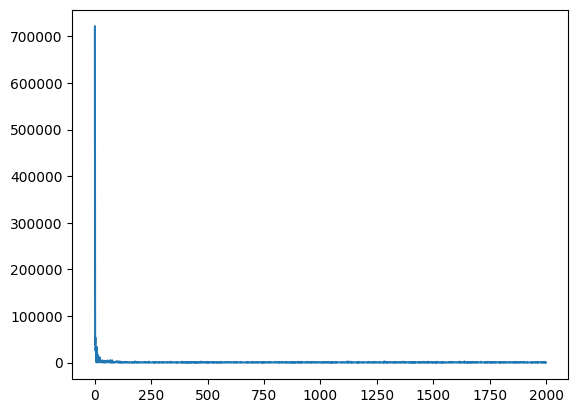

69


In [372]:
import matplotlib.pyplot as plt

ENV_NAME = "final_boss" # One of: original, bridge, switchback, long_hall, minefield, final_boss
env = IceSkating(ENVIRONMENTS[ENV_NAME])

# Array shape follows the environment: (y, x, vy, vx, action)
n_vel = 2 * env.MAX_VEL + 1 # Velocities from -MAX_VEL to MAX_VEL
shape = (*env.grid.shape, n_vel, n_vel, len(env.actions))
policy = np.full(shape, 1 / len(env.actions), dtype=np.float32) # Initialise as uniform
q_values = np.zeros(shape, dtype=np.float32)

EPSILON = 0.1
DISCOUNT_RATE = 0.99
EPISODES = 2000
LEARNING_RATE = 0.1

q_learning = QLearning(policy, q_values, EPSILON, DISCOUNT_RATE, env, EPISODES, LEARNING_RATE)

hist = q_learning.learn()

plt.plot(hist)
plt.show()

print(min(hist))

In [373]:
import math
from matplotlib import animation, colors
from IPython.display import HTML

CELL_CODES = {"o": 0, "s": 1, "g": 2, "x": 3, "h": 4}
CELL_CMAP = colors.ListedColormap(["#e8f1f8",   # open ice
                                   "#a3d9a5",   # start
                                   "#f2c14e",   # goal
                                   "#3b4252",   # wall
                                   "#b23a48"])  # hole


def greedy_path(env, q_values, max_steps=200):
    """Run one episode following argmax Q, recording positions like QLearning.paths."""
    goal = tuple(np.argwhere(env.grid == "g")[0])
    env.restart()
    state = env.get_state()
    path = [state[:2]]
    for _ in range(max_steps):
        state, reward = env.step(np.argmax(q_values[state]))
        if reward == -1:
            path.append((np.nan, np.nan))
        path.append(goal if reward == 1 else state[:2])
        if reward == 1:
            break
    return np.array(path, dtype=float)


def draw_grid(ax, grid):
    ax.imshow(np.vectorize(CELL_CODES.get)(grid), cmap=CELL_CMAP, vmin=-0.5, vmax=4.5)
    ax.set_xticks(np.arange(-0.5, grid.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, grid.shape[0]), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)


def plot_learning_curve(history, window=20):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(history, color="#9db4c8", linewidth=0.8, label="steps per episode")
    if len(history) >= window:
        smooth = np.convolve(history, np.ones(window) / window, mode="valid")
        ax.plot(np.arange(window - 1, len(history)), smooth, color="#1d4e89",
                linewidth=2, label=f"{window}-episode average")
    ax.set_yscale("log")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Steps to goal (log)")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()


def animate_paths(paths, titles, grid=GRID, max_frames=100, interval=120):
    """Animate several paths side by side. Long paths are sped up to fit in max_frames."""
    n = len(paths)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.8), dpi=80)
    axes = np.atleast_1d(axes)
    strides = [max(1, math.ceil(len(p) / max_frames)) for p in paths]
    n_frames = max(math.ceil(len(p) / s) for p, s in zip(paths, strides)) + 5  # hold the end briefly

    artists = []
    for ax, p, title, stride in zip(axes, paths, titles, strides):
        draw_grid(ax, grid)
        steps = int(np.sum(~np.isnan(p[:, 0]))) - 1
        falls = int(np.sum(np.isnan(p[:, 0])))
        subtitle = f"{steps} steps, {falls} falls" + (f"  (x{stride} speed)" if stride > 1 else "")
        ax.set_title(f"{title}\n{subtitle}", fontsize=10)
        line, = ax.plot([], [], color="#1d4e89", linewidth=1.5, alpha=0.6)
        dot, = ax.plot([], [], "o", color="#1d4e89", markersize=9,
                       markeredgecolor="white", markeredgewidth=1.5)
        artists.append((p, stride, line, dot))

    def update(frame):
        for p, stride, line, dot in artists:
            seg = p[:min(frame * stride, len(p) - 1) + 1]
            line.set_data(seg[:, 1], seg[:, 0])
            last = seg[~np.isnan(seg[:, 0])][-1]
            dot.set_data([last[1]], [last[0]])
        return [a for _, _, line, dot in artists for a in (line, dot)]

    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.84, wspace=0.08)
    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=interval, blit=True)
    plt.close(fig)
    return HTML(anim.to_jshtml())

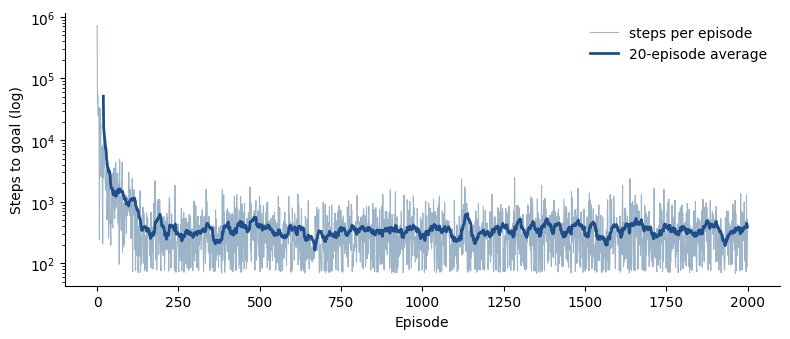

In [374]:
plot_learning_curve(q_learning.history)

episodes_to_show = [0, 49, len(q_learning.paths) - 1] # Change these to view other episodes
paths = [q_learning.paths[i] for i in episodes_to_show] + [greedy_path(env, q_values)]
titles = [f"Episode {i + 1}" for i in episodes_to_show] + ["Greedy policy"]
animate_paths(paths, titles, grid=env.grid)